# Coloración de grafos

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras -  A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

## Grafo planteado

En este caso, se plantea un grafo con 19 nodos; como se muestra en la siguiente Figura:

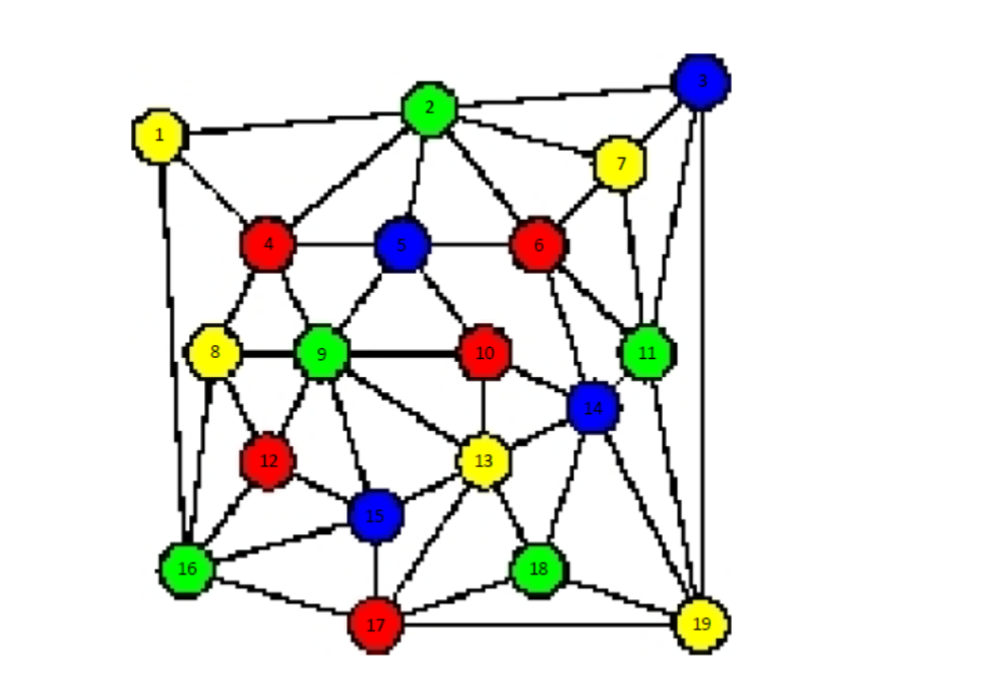

Se busca obtener el menor número de colores tal que nodos adyacentes no tengan el mismo color mediante un algoritmo genético.

In [179]:
import numpy as np
import time

# Total de vértices
num_vertices = 19

# Lista de aristas obtenidas del grafo (1-indexadas)
edges = [
    (1, 2), (1, 4), (1, 8), (1, 16),
    (2, 3), (2, 4), (2, 5), (2, 6), (2, 7),
    (3, 7), (3, 11), (3, 19),
    (4, 5), (4, 8), (4, 9),
    (5, 6), (5, 9), (5, 10),
    (6, 7), (6, 10), (6, 11), (6, 14),
    (7, 11),
    (8, 9), (8, 12), (8, 16),
    (9, 10), (9, 12), (9, 13), (9, 15),
    (10, 13), (10, 14),
    (11, 14), (11, 19),
    (12, 15), (12, 16),
    (13, 14), (13, 15), (13, 17), (13, 18),
    (14, 18), (14, 19),
    (15, 16), (15, 17),
    (16, 17),
    (17, 18), (17, 19),
    (18, 19)
]

# Crear matriz de ceros de 19x19
adj_matrix = np.zeros((num_vertices, num_vertices), dtype=int)

# Llenar la matriz de adyacencia (convertir a 0-indexado)
for u, v in edges:
    adj_matrix[u-1][v-1] = 1
    adj_matrix[v-1][u-1] = 1  # Grafo no dirigido

print("Matriz de Adyacencia (19x19):")
print(adj_matrix)

Matriz de Adyacencia (19x19):
[[0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0]
 [1 0 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1]
 [1 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 0]
 [0 1 0 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0]
 [0 1 0 0 1 0 1 0 0 1 1 0 0 1 0 0 0 0 0]
 [0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0]
 [0 0 0 1 1 0 0 1 0 1 0 1 1 0 1 0 0 0 0]
 [0 0 0 0 1 1 0 0 1 0 0 0 1 1 0 0 0 0 0]
 [0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 1]
 [0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1 0 0 0]
 [0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 1 0]
 [0 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 1]
 [0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 0 0]
 [1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 1 1]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1]
 [0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 0]]


In [180]:

def fitness_function(individuo, adj_matrix):
    mismo_color = (individuo[:, None] == individuo[None, :])
    conflictos = np.sum((adj_matrix == 1) & mismo_color) // 2
    
    colores_usados = len(np.unique(individuo))
    score = 1.0 / (1.0 + (conflictos * 10) + 5 * colores_usados)
    
    return score

def ruleta(fitness_values):
    total_fitness = np.sum(fitness_values) 
    
    probabilities = fitness_values / total_fitness
        
    padres = np.random.choice(len(fitness_values), size=2, p=probabilities, replace=False)
    return padres[0], padres[1]

def cruza_mitad(padre1, padre2):
    # Genera una máscara de valores booleanos (True/False)
    mascara = np.random.rand(len(padre1)) < 0.5
    
    # hijo1 toma de padre1 donde es True, y de padre2 donde es False
    hijo1 = np.where(mascara, padre1, padre2)
    # hijo2 hace lo opuesto
    hijo2 = np.where(mascara, padre2, padre1)
    
    return hijo1, hijo2

def mutacion(hijo, num_colores, tasa_mutacion=0.05):
    hijo_mutado = np.copy(hijo)
    for i in range(len(hijo_mutado)):
        if np.random.rand() < tasa_mutacion:
            # Seleccionar un color aleatorio diferente al actual
            colores_disponibles = [c for c in range(num_colores) if c != hijo_mutado[i]]
            hijo_mutado[i] = np.random.choice(colores_disponibles)
    return hijo_mutado

In [181]:
def ejecutar_genetico(n, adj_matrix, num_vectores=100, num_iteraciones=10000):
    tasa_mutacion = 0.05  # Probabilidad de mutación
    
    # Inicialización Aleatoria Uniforme
    cromosoma = np.random.randint(0, n -1, size=(num_vectores, n))
    
    # Evaluar la población inicial
    fitness_poblacion = np.array([fitness_function(V, adj_matrix) for V in cromosoma])

    historial_mejor_fitness = []

    # Iniciar cronómetro
    start_time = time.time()
    
    # Ciclo de Estado Estacionario
    for _ in range(num_iteraciones):
        
        # 1. Selección (Ruleta)
        idx_p1, idx_p2 = ruleta(fitness_poblacion)
        padre1 = cromosoma[idx_p1]
        padre2 = cromosoma[idx_p2]
        
        # 2. Cruza (1 punto a la mitad)
        hijo1, hijo2 = cruza_mitad(padre1, padre2)
        
        # 3. Mutación
        hijo1 = mutacion(hijo1, n - 1, tasa_mutacion)
        hijo2 = mutacion(hijo2, n - 1, tasa_mutacion)
    
        # 4. Evaluar hijos
        fit_h1 = fitness_function(hijo1, adj_matrix)
        fit_h2 = fitness_function(hijo2, adj_matrix)
        
        # 5. REEMPLAZO: Encontrar los 2 peores individuos
        # argsort ordena de menor a mayor fitness, tomamos los 2 primeros índices
        indices_peores = np.argsort(fitness_poblacion)[:2]
        
        # Sustituir a los 2 peores con los nuevos hijos
        cromosoma[indices_peores[0]] = hijo1
        fitness_poblacion[indices_peores[0]] = fit_h1
        
        cromosoma[indices_peores[1]] = hijo2
        fitness_poblacion[indices_peores[1]] = fit_h2

        mejor_actual = np.max(fitness_poblacion)
        historial_mejor_fitness.append(mejor_actual)
        
    # Detener cronómetro
    end_time = time.time()
    tiempo_cpu = end_time - start_time
    
    # Buscar el mejor individuo histórico que quedó en la población final
    mejor_idx = np.argmax(fitness_poblacion)
    mejor_vector = cromosoma[mejor_idx]
    mejor_fitness = fitness_poblacion[mejor_idx]
    colores_usados = len(np.unique(cromosoma[mejor_idx]))
    
    return (mejor_vector, mejor_fitness, tiempo_cpu, 
            cromosoma, fitness_poblacion, historial_mejor_fitness, colores_usados)

In [184]:
for i in range(10):
    mejor_vector, mejor_fitness, tiempo, _, _, _, colores = ejecutar_genetico(num_vertices, adj_matrix)
    print(f"Mejor coloreado: {mejor_vector}")
    print(f"Mejor fitness: {mejor_fitness:.4f}")
    print(f"Tiempo de ejecución: {tiempo:.4f}s")
    print(f"Colores utilizados: {colores}")

Mejor coloreado: [10  6  1  1 12 10 12 12 17  6  6 10 10  1 12  1  6 12 10]
Mejor fitness: 0.0385
Tiempo de ejecución: 0.7011s
Colores utilizados: 5
Mejor coloreado: [ 2 10  9  9  2  0  2  1  0  9 10  9 10  1  1 10  9  0  2]
Mejor fitness: 0.0385
Tiempo de ejecución: 0.7261s
Colores utilizados: 5
Mejor coloreado: [ 9 12 13  6 13 15  9 12 16  9  6 15 15 12  9 13  6 13 16]
Mejor fitness: 0.0323
Tiempo de ejecución: 0.7164s
Colores utilizados: 6
Mejor coloreado: [ 8  1  0  6  0  6 15  1 15  8  8  8  0  1  6 15  8  6 15]
Mejor fitness: 0.0385
Tiempo de ejecución: 0.7152s
Colores utilizados: 5
Mejor coloreado: [ 9  7  2 14  2  4  9  2  4  9 14  7  7  2  9  4 14  4  7]
Mejor fitness: 0.0385
Tiempo de ejecución: 0.7222s
Colores utilizados: 5
Mejor coloreado: [ 2  0  2 11  5  2  5  5  2  0 11 13  5 13 11  0 13  2  5]
Mejor fitness: 0.0385
Tiempo de ejecución: 0.6989s
Colores utilizados: 5
Mejor coloreado: [ 9 14 11 17 11  9  7  7  9  7 17 11 14 11 17 14  7 17  9]
Mejor fitness: 0.0385
Tiempo d